# Q13. In which brain area is the dimensionality of neural activity highest? (stimulus → outcome)

**Dimensionality** is how many independent directions the population's activity really explores. If all units rise and fall together, activity lies along one dimension. If every unit fluctuates on its own, there are as many dimensions as units.

**Measure: participation ratio (PR)** of the eigenvalues λ of the units' correlation matrix: PR = (Σλ)² / Σλ².
It ranges from 1 (all units co-vary) to N (independent units). On simulated data, 5 independent units give PR = 4.99, and 5 units driven by one shared signal give PR = 1.9.

**Data:**
- stimulus → outcome segments, cut into **50-ms bins**, concatenated across trials. Only **trials whose segment is ≤ 2 s** are used (about 90% of trials, see section 0);
- spike counts **z-scored** per unit (a correlation matrix), so fast-firing units don't dominate.

**PR can't exceed the number of units**, and areas have different numbers of recorded units. So each area uses the **same number of units**: 5 (all 18 mice) and 10 (the 14 mice with ≥ 10 active units in every area), each drawn at random 200 times.

**Robustness checks:**
- 20- and 100-ms bins;
- the first 1 s of every segment, and all stimulus → outcome time without any limit;
- the covariance matrix (raw counts);
- the number of principal components needed for 80% of the variance.

The code lives in `c2p/q13_dimensionality.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as sps

from c2p import AREAS, AREA_COLORS, RESULTS_DIR, Recording
from c2p import q13_dimensionality as q
from c2p.stats import area_bootstrap, per_mouse_tests

dim = q.compute()                         # cached; q.compute(force=True) recomputes (~15 min)
MAIN = "trials <= 2 s"
main = dim[(dim.variant == MAIN) & (dim.bin_s == 0.05) & (dim.n_units == 5)]
print(f"50-ms bins per mouse (stimulus → outcome, all trials): {main.groupby('mouse').n_bins.first().describe()[['min', '50%', 'max']].to_dict()}")

50-ms bins per mouse (stimulus → outcome, all trials): {'min': 2682.0, '50%': 4019.0, 'max': 5879.0}


## 0. Why segments longer than 2 s are left out

The median stimulus → outcome segment lasts 0.3–0.6 s, but a few last minutes. Ten mice have one of ~22 minutes, which looks like a pause in the session.
In most mice, trials longer than 2 s make up the **majority of all stimulus → outcome time**, so without a limit those long waits would dominate the estimate.

In [2]:
rows = []
from c2p import DATA_DIR, mice
for m in mice():
    t = pd.read_csv(DATA_DIR / str(m) / "trial_data.csv", index_col=0, encoding="utf-8-sig").dropna()
    s2 = t.outcome - t.stim_start
    rows.append({"mouse": m, "median (s)": s2.median(), "max (s)": s2.max(), "% trials ≤ 2 s": 100 * (s2 <= 2).mean(),
                 "% of stim→outcome time in trials > 2 s": 100 * s2[s2 > 2].sum() / s2.sum()})
pd.DataFrame(rows).set_index("mouse").round(1).T

mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
median (s),0.4,0.4,0.6,0.3,0.6,0.3,0.9,0.4,0.4,0.5,0.5,1.2,0.3,0.4,0.3,0.4,0.3,0.4
max (s),1355.6,35.8,34.5,2.4,1336.1,52.2,1312.2,1323.3,1402.7,1352.0,38.5,1399.0,33.0,1393.0,1325.0,60.0,60.0,13.1
% trials ≤ 2 s,87.0,89.2,78.0,99.8,70.3,93.4,63.0,86.4,86.9,79.5,76.8,55.1,90.5,93.3,87.8,88.5,97.3,87.0
% of stim→outcome time in trials > 2 s,90.7,61.0,74.7,1.4,92.5,75.9,95.1,89.7,92.8,88.1,79.0,95.0,73.7,91.8,93.1,80.9,54.9,59.0


## 1. Eigenvalue spectra (10 units, one example mouse)

These are the sorted eigenvalues of the correlation matrix, as a fraction of the total variance, averaged over 200 random sets of 10 units.
A flatter spectrum means variance is spread over more dimensions, and so a higher PR. The dashed line is what fully independent units would give.

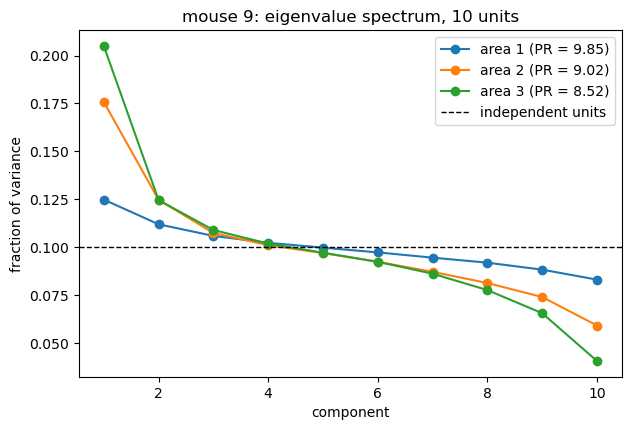

In [3]:
MOUSE = 9
rec = Recording.load(MOUSE)
X = q.segment_bins(rec, 0.05, **q.VARIANTS[MAIN])
areas = np.asarray(rec.areas)
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 4.5))
for a in AREAS:
    idx = np.flatnonzero((areas == a) & (X.std(0) > 0))
    spec = []
    for _ in range(200):
        _, lam = q.participation_ratio(X[:, rng.choice(idx, 10, replace=False)])
        spec.append(np.sort(lam)[::-1] / lam.sum())
    pr = np.mean([q.participation_ratio(X[:, rng.choice(idx, 10, replace=False)])[0] for _ in range(200)])
    ax.plot(range(1, 11), np.mean(spec, 0), "-o", color=AREA_COLORS[a], label=f"area {a} (PR = {pr:.2f})")
ax.axhline(0.1, color="k", ls="--", lw=1, label="independent units")
ax.set(xlabel="component", ylabel="fraction of variance", title=f"mouse {MOUSE}: eigenvalue spectrum, 10 units")
ax.legend()

## 2. Mouse by mouse (main: trials ≤ 2 s, 50-ms bins, 5 units)

Friedman p = 7.1e-05


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,15,18,8.4e-04,0.002518
area 1 vs area 3,17,18,2.5e-04,0.000755
area 2 vs area 3,13,18,3.4e-02,0.102699


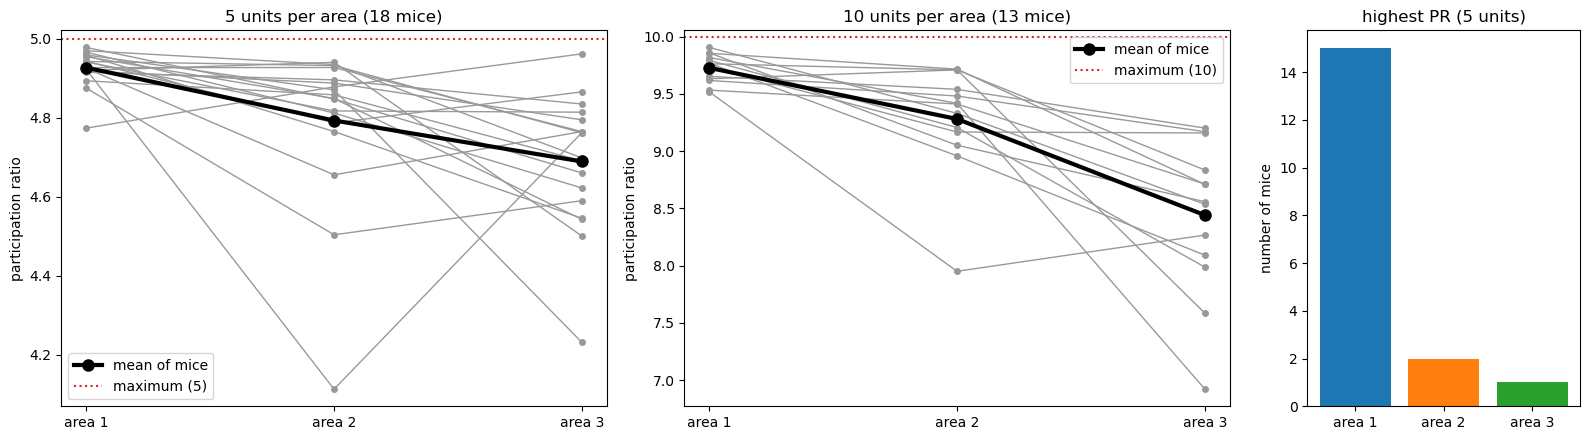

In [4]:
per_mouse, friedman, wilc = per_mouse_tests(main, "pr_corr")
best = per_mouse.idxmax(axis=1).value_counts().reindex(AREAS, fill_value=0)
ten = dim[(dim.variant == MAIN) & (dim.bin_s == 0.05) & (dim.n_units == 10)].pivot(index="mouse", columns="area", values="pr_corr").dropna()
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw=dict(width_ratios=[2, 2, 1]))
for ax, (t, n) in zip(axs[:2], [(per_mouse, 5), (ten, 10)]):
    for m, row in t.iterrows():
        ax.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
    ax.plot(AREAS, t.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
    ax.axhline(n, color="tab:red", ls=":", label=f"maximum ({n})")
    ax.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="participation ratio",
           title=f"{n} units per area ({len(t)} mice)"); ax.legend()
axs[2].bar([f"area {a}" for a in AREAS], best.values, color=[AREA_COLORS[a] for a in AREAS])
axs[2].set(ylabel="number of mice", title="highest PR (5 units)")
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
wilc.style.format({"wilcoxon p": "{:.1e}"})

## 3. Mean and 95% CI (bootstrap over mice)

In [5]:
t_main, _ = area_bootstrap(main, "pr_corr")
t_main.round(3)

,estimate,ci_low,ci_high,p (diff = 0)
area 1,4.927,4.903,4.945,NaN
area 2,4.793,4.692,4.868,NaN
area 3,4.690,4.612,4.761,NaN
area 1 − area 2,0.134,0.056,0.234,0.000
area 1 − area 3,0.237,0.153,0.325,0.000
area 2 − area 3,0.104,-0.021,0.220,0.095


## 4. Robustness

In [6]:
rows = {}
for (v, b, n), g in dim.groupby(["variant", "bin_s", "n_units"]):
    for col, lab in [("pr_corr", "PR (correlation)"), ("pr_cov", "PR (covariance)"), ("k80", "components for 80%")]:
        t = g.pivot(index="mouse", columns="area", values=col).dropna()
        w = {f"{x} vs {y}": sps.wilcoxon(t[x], t[y]).pvalue for x, y in [(1, 2), (1, 3)]}
        rows[f"{v}, {1000 * b:.0f} ms, {n} units, {lab}"] = {
            **{f"area {a}": t[a].mean() for a in AREAS}, "mice": len(t),
            "highest in n mice": dict(t.idxmax(axis=1).value_counts().sort_index()),
            "Friedman p": sps.friedmanchisquare(*[t[a] for a in AREAS]).pvalue,
            "Wilcoxon 1 vs 2": w["1 vs 2"], "Wilcoxon 1 vs 3": w["1 vs 3"]}
robust = pd.DataFrame(rows).T
robust

,area 1,area 2,area 3,mice,highest in n mice,Friedman p,Wilcoxon 1 vs 2,Wilcoxon 1 vs 3
"all time, 20 ms, 5 units, PR (correlation)",4.971805,4.902715,4.777518,18,"{1: 15, 2: 2, 3: 1}",0.000008,0.000076,0.000053
"all time, 20 ms, 5 units, PR (covariance)",3.917375,3.248069,3.280149,18,"{1: 14, 3: 4}",0.000618,0.000252,0.0056
"all time, 20 ms, 5 units, components for 80%",3.996667,3.996667,3.958611,18,"{1: 17, 2: 1}",0.00376,0.500184,0.021739
"all time, 20 ms, 10 units, PR (correlation)",9.861295,9.657494,8.881446,14,"{1: 11, 2: 2, 3: 1}",0.000142,0.005249,0.000854
"all time, 20 ms, 10 units, PR (covariance)",7.561043,5.729119,5.324478,14,"{1: 13, 3: 1}",0.000416,0.002319,0.010742
"all time, 20 ms, 10 units, components for 80%",7.975357,7.956429,7.578929,14,"{1: 13, 2: 1}",0.000219,0.500184,0.004742
"all time, 50 ms, 5 units, PR (correlation)",4.939602,4.740135,4.649293,18,"{1: 16, 2: 1, 3: 1}",0.000014,0.000038,0.000053
"all time, 50 ms, 5 units, PR (covariance)",3.818157,3.11008,3.097364,18,"{1: 14, 2: 1, 3: 3}",0.000618,0.000107,0.002808
"all time, 50 ms, 5 units, components for 80%",3.996944,3.991389,3.939167,18,"{1: 16, 2: 2}",0.005594,0.267584,0.007602
"all time, 50 ms, 10 units, PR (correlation)",9.721049,9.174556,8.376512,14,"{1: 12, 2: 1, 3: 1}",0.000034,0.000244,0.00061


## 5. Answer for the questionnaire

In [7]:
from c2p.questionnaire import fill_pdf, record_answer, record_meta

answer = t_main.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
rows_q = [(f"{r.Mean:.3f}", f"[{r['CI low']:.3f}, {r['CI high']:.3f}]", "PR (max 5)") for _, r in answer.iterrows()]
answer.to_csv(RESULTS_DIR / "q13_answer.csv")
m = t_main.estimate
n_area1 = robust["highest in n mice"].apply(lambda d: d.get(1, 0) / sum(d.values()))
expl = (
    f"Stimulus -> outcome segments were cut into 50-ms bins and the bins of all trials were concatenated, giving a bins "
    f"x units matrix of spike counts per mouse; trials with segments longer than 2 s (a few last minutes, i.e. pauses) "
    f"were excluded. Dimensionality was measured as the participation ratio, "
    f"PR = (sum of eigenvalues)^2 / (sum of squared eigenvalues), of the units' correlation matrix; PR ranges from 1 "
    f"(all units co-vary) to the number of units (independent units). Because PR is bounded by the number of units, "
    f"each area used the same number of units (5, the smallest area; 200 random draws), and values are means over mice "
    f"with a bootstrap CI. Area 1 had the highest dimensionality (PR {m['area 1']:.2f} vs {m['area 2']:.2f} in area 2 "
    f"and {m['area 3']:.2f} in area 3, maximum 5), in {int(best[1])} of 18 mice (Friedman p < 0.001; Wilcoxon p "
    f"<= {min(1, 3 * max(wilc.loc['area 1 vs area 2', 'wilcoxon p'], wilc.loc['area 1 vs area 3', 'wilcoxon p'])):.3f} "
    f"against each area). The same held "
    f"with 10 units per area ({len(ten)} mice; PR {ten[1].mean():.2f}, {ten[2].mean():.2f}, {ten[3].mean():.2f} of 10), with "
    f"20- and 100-ms bins, with the first 1 s of every segment or all time, with the covariance instead of the "
    f"correlation matrix, and with the number of components "
    f"explaining 80% of the variance (area 1 highest in {n_area1.min() * 100:.0f}-{n_area1.max() * 100:.0f}% of mice "
    f"across these variants). Area 1 units therefore fluctuate most independently, in line with their weaker pairwise "
    f"correlations; this is not a noise effect, since area 1 also has the highest firing rates."
)
expl += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(expl.split()), "words"); print(expl)
record_answer(13, choice=0, rows=rows_q, explanation=expl)  # 0 = area 1
record_meta(13, confidence=6, consensus=5)
print(fill_pdf())

247 words
Stimulus -> outcome segments were cut into 50-ms bins and the bins of all trials were concatenated, giving a bins x units matrix of spike counts per mouse; trials with segments longer than 2 s (a few last minutes, i.e. pauses) were excluded. Dimensionality was measured as the participation ratio, PR = (sum of eigenvalues)^2 / (sum of squared eigenvalues), of the units' correlation matrix; PR ranges from 1 (all units co-vary) to the number of units (independent units). Because PR is bounded by the number of units, each area used the same number of units (5, the smallest area; 200 random draws), and values are means over mice with a bootstrap CI. Area 1 had the highest dimensionality (PR 4.93 vs 4.79 in area 2 and 4.69 in area 3, maximum 5), in 15 of 18 mice (Friedman p < 0.001; Wilcoxon p <= 0.003 against each area). The same held with 10 units per area (13 mice; PR 9.73, 9.28, 8.44 of 10), with 20- and 100-ms bins, with the first 1 s of every segment or all time, with the cov

/home/dariosannino/con2phys/docs/questionnaire_filled.pdf


## Conclusion

**Area 1 has the highest dimensionality.** Its units vary most independently of each other, and this holds for every bin width, matrix type, measure and population size.
Areas 2 and 3 are lower and close to each other.

The effect is modest in absolute terms (with 5 units, every area is close to the maximum of 5), but it is very consistent across mice.

Confidence 6/10. Dimensionality estimates are known to depend on choices like normalisation and the number of units, although here every variant agrees.